# Phase 3A: Teams

This notebook looks at the NHL at the team level for the ten seasons from 2010-11 to 2019-20. It starts with a short recap of each season, then asks what separated good teams from bad ones and which team stats actually go with winning.

**Questions**
1. How did the league change from season to season? *(Season recap)*
2. Which teams were strongest over the decade, how consistent were they, and did regular-season success carry into the playoffs? *(Team results)*
3. Which parts of the game go with winning: shooting and goaltending, shot volume, special teams, discipline, faceoffs, puck possession, or physical play? *(What wins)*
4. Which of those stats carry over from one season to the next? *(Repeatability)*
5. Did changing the coach in mid-season help? *(Coaching changes)*

Home-ice advantage, hits and icing each have their own notebook, so they only appear here as context.

All results describe associations in the data, not causes. Team stats such as hits and blocks are also affected by the score: a team that is leading tends to sit back, block shots and get outshot, so a stat that goes with winning is not necessarily a stat that causes winning.

## Setup

`eda_utils.py` (in this folder) opens the Phase 1 tables and sets the chart style. The cell below also builds `team_season`: one row per franchise per regular season, with the rates used throughout the notebook.

- **Points %** is standings points earned divided by points available (2 per game). Overtime and shootout losses earn a point, so the league average is about 0.56, not 0.50.
- **Shooting %** and **save %** are team goals divided by team shots on goal, at all strengths, so they include empty-net goals.
- **PDO** is shooting % plus save %. It averages about 1.00 and is often used as a rough measure of luck.
- **Shot share** is a team's shots divided by all shots in its games. It is a simple stand-in for puck possession.
- **PP %** is power-play goals divided by power-play opportunities, and **PK %** is the share of the opponent's power plays that did not end in a goal.

In [1]:
from eda_utils import *
con, q = connect()
save = figure_saver("3a_teams")

con.execute("""
CREATE OR REPLACE VIEW team_season AS
SELECT f.franchise, t.season, CAST(substr(t.season, 1, 4) AS INT) AS season_start_year,
       count(*) AS gp, sum(t.standings_points) AS points,
       sum(t.standings_points) / (2.0 * count(*)) AS points_pct,
       avg(t.won::INT) AS win_pct,
       avg(t.goals_for) AS gf_pg, avg(t.goals_against) AS ga_pg,
       avg(t.goals_for - t.goals_against) AS goal_diff_pg,
       avg(t.shots_for) AS sf_pg, avg(t.shots_against) AS sa_pg,
       sum(t.shots_for) / sum(t.shots_for + t.shots_against) AS shot_share,
       sum(t.goals_for) / sum(t.shots_for) AS sh_pct,
       1 - sum(t.goals_against) / sum(t.shots_against) AS sv_pct,
       sum(t.goals_for) / sum(t.shots_for) + 1 - sum(t.goals_against) / sum(t.shots_against) AS pdo,
       sum(t.pp_goals) / sum(t.pp_opportunities) AS pp_pct,
       1 - sum(t.opp_pp_goals) / sum(t.opp_pp_opportunities) AS pk_pct,
       avg(t.pp_opportunities) AS pp_opps_pg, avg(t.opp_pp_opportunities) AS pk_times_pg,
       avg(t.pp_opportunities - t.opp_pp_opportunities) AS pp_opp_diff_pg,
       avg(t.faceoff_win_pct) AS faceoff_pct,
       avg(t.hits) AS hits_pg, avg(t.hits - t.opp_hits) AS hit_diff_pg,
       avg(t.takeaways - t.opp_takeaways) AS takeaway_diff_pg,
       avg(t.giveaways - t.opp_giveaways) AS giveaway_diff_pg,
       avg(t.blocked_shots - t.opp_blocked_shots) AS block_diff_pg,
       avg(t.pim) AS pim_pg
FROM fact_team_game t JOIN franchise f USING (team_id)
WHERE t.game_type = 'Regular'
GROUP BY ALL""")

ts = q("SELECT * FROM team_season ORDER BY franchise, season")
print(f"{len(ts)} team-seasons, {ts.franchise.nunique()} franchises")
ts.head()

303 team-seasons, 31 franchises


,franchise,season,season_start_year,gp,points,points_pct,win_pct,gf_pg,ga_pg,goal_diff_pg,sf_pg,sa_pg,shot_share,sh_pct,sv_pct,pdo,pp_pct,pk_pct,pp_opps_pg,pk_times_pg,pp_opp_diff_pg,faceoff_pct,hits_pg,hit_diff_pg,takeaway_diff_pg,giveaway_diff_pg,block_diff_pg,pim_pg
0,ANA,2010-11,2010,82,99.000,0.604,0.573,2.866,2.841,0.024,28.463,32.305,0.468,0.101,0.912,1.013,0.235,0.813,3.476,3.720,-0.244,0.476,23.610,1.695,-1.000,-1.390,4.561,14.366
1,ANA,2011-12,2011,82,80.000,0.488,0.415,2.451,2.732,-0.280,27.951,28.866,0.492,0.088,0.905,0.993,0.166,0.820,3.305,3.451,-0.146,0.474,22.634,0.061,-0.976,-0.134,0.939,11.951
2,ANA,2012-13,2012,48,66.000,0.688,0.625,2.792,2.396,0.396,28.062,27.917,0.501,0.099,0.914,1.014,0.215,0.815,2.812,3.375,-0.562,0.475,23.938,0.979,-0.062,-0.542,2.583,11.146
3,ANA,2013-14,2013,82,116.000,0.707,0.659,3.207,2.476,0.732,31.329,28.707,0.522,0.102,0.914,1.016,0.160,0.822,3.354,3.293,0.061,0.493,24.683,-0.159,0.146,-0.500,1.500,10.902
4,ANA,2014-15,2014,82,109.000,0.665,0.622,2.780,2.695,0.085,29.976,28.866,0.509,0.093,0.907,0.999,0.157,0.810,2.866,3.341,-0.476,0.516,28.061,1.390,-0.439,-0.537,0.256,10.817


# 1. Season Recap

### 1.1 The ten seasons at a glance

One row per regular season, using league averages per team per game. Three seasons were unusual: 2012-13 was cut to 48 games by a lockout, Vegas joined in 2017-18 to make 31 teams, and 2019-20 stopped in March because of COVID-19 and finished with a 24-team playoff in two neutral-site bubbles.

In [2]:
recap = q("""
    SELECT s.season, s.games, round(s.goals_pg, 2) AS goals_pg, round(s.shots_pg, 1) AS shots_pg,
           round(s.shooting_pct, 3) AS shooting_pct, round(s.pp_opps_pg, 2) AS pp_opps_pg,
           round(s.pp_pct, 3) AS pp_pct, round(s.hits_pg, 1) AS hits_pg, round(s.pim_pg, 1) AS pim_pg,
           round(ot.ot_so_share, 3) AS ot_so_share, round(ot.so_share, 3) AS shootout_share
    FROM league_season s
    JOIN (SELECT season, avg((settled_in IN ('OT', 'SO'))::INT) AS ot_so_share, avg((settled_in = 'SO')::INT) AS so_share
          FROM fact_game WHERE game_type = 'Regular' GROUP BY 1) ot USING (season)
    WHERE s.game_type = 'Regular' ORDER BY s.season""")
recap["note"] = recap.season.map({"2012-13": "48-game lockout season", "2017-18": "Vegas joins (31 teams)",
                                  "2019-20": "stopped in March (COVID-19)"}).fillna("")
recap

,season,games,goals_pg,shots_pg,shooting_pct,pp_opps_pg,pp_pct,hits_pg,pim_pg,ot_so_share,shootout_share,note
0,2010-11,1230,2.730,30.400,0.090,3.540,0.180,22.700,12.300,0.241,0.121,
1,2011-12,1230,2.660,29.800,0.089,3.310,0.173,22.800,11.200,0.244,0.147,
2,2012-13,720,2.650,29.100,0.091,3.320,0.182,23.800,11.600,0.225,0.135,48-game lockout season
3,2013-14,1230,2.670,30.000,0.089,3.270,0.179,23.500,10.900,0.250,0.145,
4,2014-15,1230,2.660,29.900,0.089,3.060,0.187,25.000,9.700,0.249,0.138,
5,2015-16,1230,2.670,29.700,0.090,3.110,0.187,23.200,9.700,0.224,0.087,
6,2016-17,1230,2.730,30.200,0.090,2.990,0.191,21.700,9.200,0.235,0.080,
7,2017-18,1271,2.930,32.000,0.092,3.040,0.202,21.600,8.600,0.233,0.081,Vegas joins (31 teams)
8,2018-19,1271,2.980,31.400,0.095,2.920,0.198,22.400,8.300,0.213,0.068,
9,2019-20,1082,2.980,31.400,0.095,2.970,0.200,21.700,8.400,0.231,0.079,stopped in March (COVID-19)


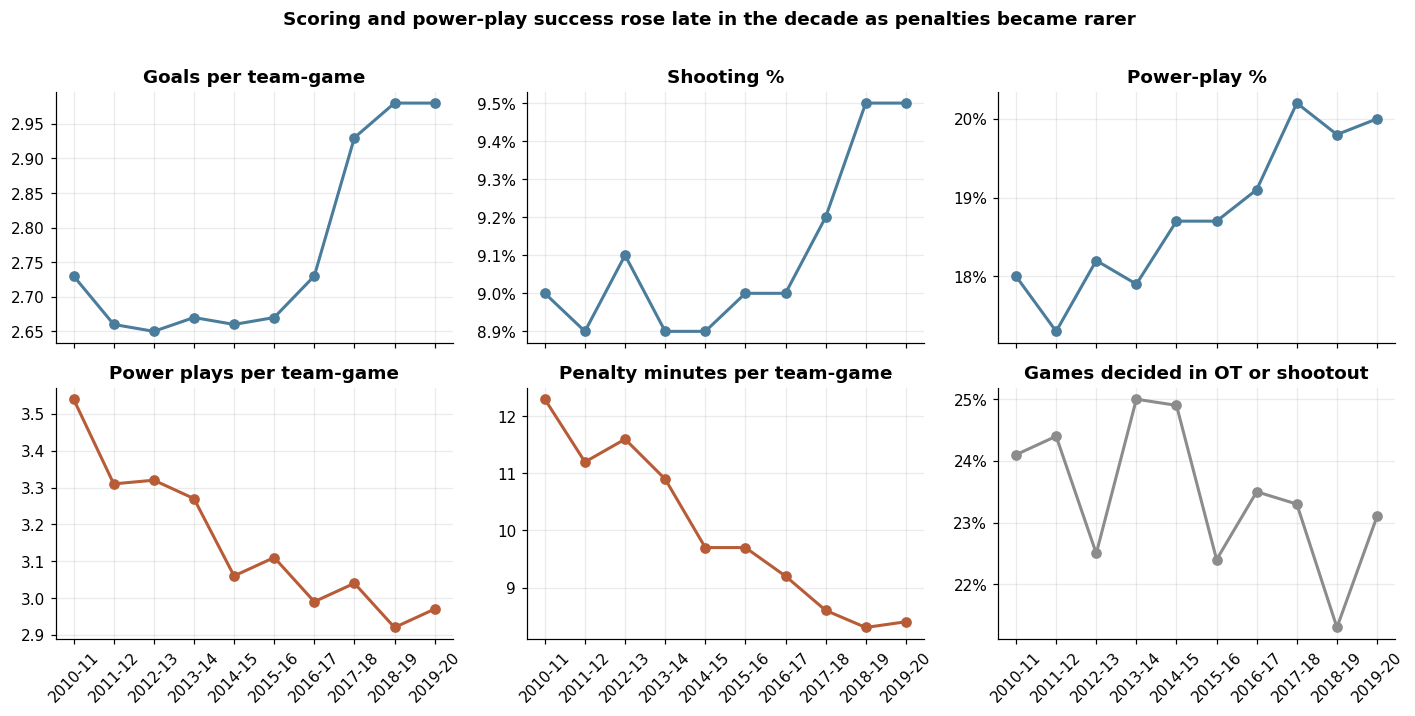

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
panels = [("goals_pg", "Goals per team-game", BLUE, None), ("shooting_pct", "Shooting %", BLUE, (1, 0.001)),
          ("pp_pct", "Power-play %", BLUE, (0, 0.01)),
          ("pp_opps_pg", "Power plays per team-game", RUST, None), ("pim_pg", "Penalty minutes per team-game", RUST, None),
          ("ot_so_share", "Games decided in OT or shootout", GREY, (0, 0.01))]
for ax, (col, title, color, pct) in zip(axes.flat, panels):
    ax.plot(recap.season, recap[col], marker="o", color=color, lw=2)
    ax.set_title(title)
    if pct is not None:
        pct_axis(ax, decimals=pct[0], step=pct[1])
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Scoring and power-play success rose late in the decade as penalties became rarer",
             fontweight="bold", y=1.01)
fig.tight_layout(); save(fig, "1_1_season_recap"); plt.show()

**Finding:** The first half of the decade was a stable, low-scoring league at about 2.66 goals per team-game. Scoring jumped to 2.93 in 2017-18 and 2.98 by 2018-19, and almost all of the jump came from finishing: shooting % rose from about 9.0% to 9.5% while shots rose only a little. Penalties fell steadily, from 3.5 power plays and 12.3 penalty minutes per team-game in 2010-11 to about 3.0 and 8.4, yet the power play got more dangerous, converting about 20% of chances by the end against 17 to 18% at the start. About one game in four went past regulation in every season, but the share settled by a shootout halved after 2015-16, when overtime switched to 3-on-3 and more games ended before a shootout.

### 1.2 Who finished first, and who won the Cup?

The best regular-season record (the Presidents' Trophy) next to the Stanley Cup winner, taken as the winner of the last playoff game of each season.

In [4]:
best = (ts.sort_values(["season", "points_pct"], ascending=[True, False]).groupby("season").head(1)
          [["season", "franchise", "points_pct"]].rename(columns={"franchise": "best_regular_season"}))
cup = q("""
    SELECT g.season, f.franchise AS cup_winner
    FROM fact_game g JOIN franchise f ON f.team_id = g.winner_team_id
    WHERE g.is_playoff
    QUALIFY row_number() OVER (PARTITION BY g.season ORDER BY g.game_start_utc DESC) = 1""")
rank = ts.assign(rank=ts.groupby("season").points_pct.rank(ascending=False, method="min"))[["season", "franchise", "rank"]]
champions = (best.merge(cup, on="season")
                 .merge(rank, left_on=["season", "cup_winner"], right_on=["season", "franchise"])
                 .drop(columns="franchise").rename(columns={"rank": "cup_winner_regular_season_rank"}))
champions["same_team"] = champions.best_regular_season == champions.cup_winner
champions

,season,best_regular_season,points_pct,cup_winner,cup_winner_regular_season_rank,same_team
0,2010-11,VAN,0.713,BOS,7.000,False
1,2011-12,VAN,0.677,LAK,13.000,False
2,2012-13,CHI,0.802,CHI,1.000,True
3,2013-14,BOS,0.713,LAK,9.000,False
4,2014-15,NYR,0.689,CHI,7.000,False
5,2015-16,WSH,0.732,PIT,4.000,False
6,2016-17,WSH,0.720,PIT,2.000,False
7,2017-18,NSH,0.713,WSH,6.000,False
8,2018-19,TBL,0.780,STL,10.000,False
9,2019-20,BOS,0.714,TBL,3.000,False


**Finding:** The team with the best regular-season record won the Stanley Cup only once in ten seasons (Chicago in 2012-13). Cup winners finished anywhere from 1st to 13th in the regular season, and Los Angeles won in 2011-12 after finishing 13th. Over a single season, the regular-season standings are a weak guide to who wins the playoffs.

# 2. Team Results

### 2.1 Which teams were strongest over the decade, and how did they win?

Goals for and against per game for each franchise across all ten regular seasons, coloured by points %. Teams above the dashed line outscored their opponents. Relocated teams appear under their current name: Atlanta under WPG and Phoenix under ARI.

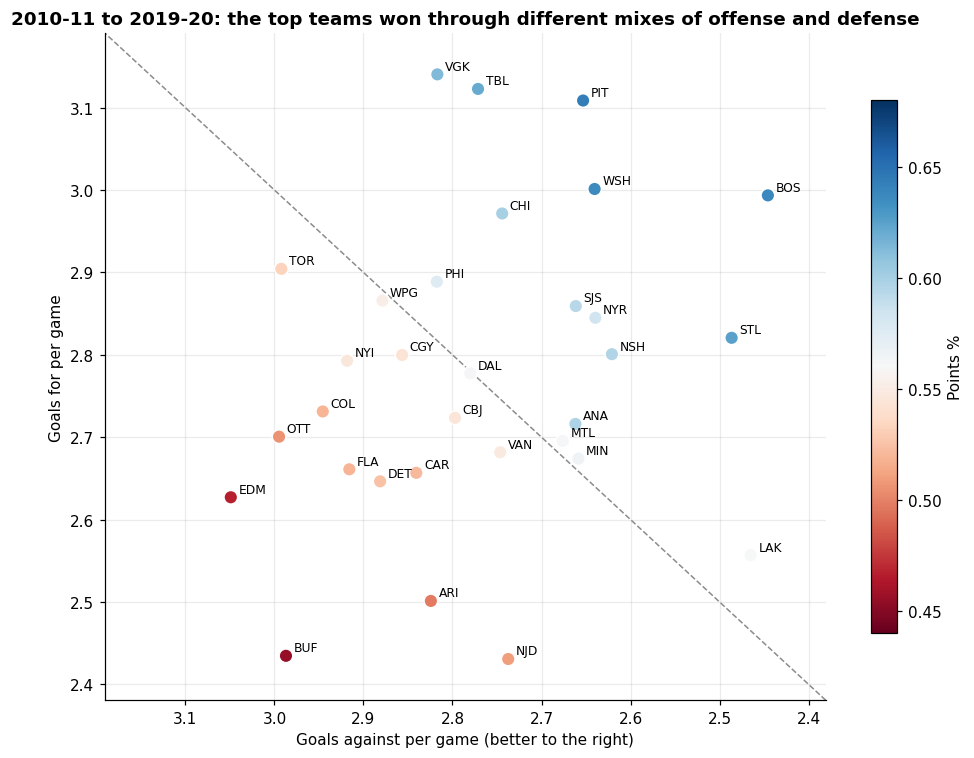

Correlation of goal differential per game with points %: 0.98


,franchise,gp,points_pct,gf_pg,ga_pg,goal_diff_pg
0,PIT,773,0.643,3.109,2.653,0.455
1,BOS,774,0.638,2.994,2.446,0.548
2,WSH,773,0.636,3.001,2.640,0.361
3,STL,775,0.625,2.821,2.486,0.334
4,TBL,774,0.620,3.123,2.771,0.351
5,VGK,235,0.613,3.140,2.817,0.323
6,CHI,774,0.599,2.972,2.744,0.227
7,ANA,775,0.597,2.716,2.662,0.054
8,NSH,773,0.596,2.801,2.621,0.180
9,SJS,774,0.594,2.859,2.661,0.198


In [5]:
teams = q("""
    SELECT f.franchise, count(*) AS gp, sum(standings_points) / (2.0 * count(*)) AS points_pct,
           avg(goals_for) AS gf_pg, avg(goals_against) AS ga_pg, avg(goals_for - goals_against) AS goal_diff_pg
    FROM fact_team_game t JOIN franchise f USING (team_id)
    WHERE game_type = 'Regular' GROUP BY 1 ORDER BY points_pct DESC""")

fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(teams.ga_pg, teams.gf_pg, c=teams.points_pct, cmap="RdBu", s=80, edgecolor="white", lw=1,
                vmin=0.44, vmax=0.68, zorder=3)
for r in teams.itertuples():
    ax.annotate(r.franchise, (r.ga_pg, r.gf_pg), xytext=(5, 3), textcoords="offset points", fontsize=8)
lims = [min(teams.ga_pg.min(), teams.gf_pg.min()) - 0.05, max(teams.ga_pg.max(), teams.gf_pg.max()) + 0.05]
ax.plot(lims, lims, color=GREY, ls="--", lw=1); ax.set_xlim(lims); ax.set_ylim(lims)
ax.invert_xaxis()
ax.set_xlabel("Goals against per game (better to the right)"); ax.set_ylabel("Goals for per game")
fig.colorbar(sc, shrink=0.8, label="Points %")
ax.set_title("2010-11 to 2019-20: the top teams won through different mixes of offense and defense")
fig.tight_layout(); save(fig, "2_1_goals_for_against"); plt.show()

print(f"Correlation of goal differential per game with points %: {teams[['goal_diff_pg', 'points_pct']].corr().iloc[0, 1]:.2f}")
teams.round(3)

**Finding:** Goal differential explains team success almost entirely: its correlation with points % across the decade is 0.98. Pittsburgh (0.643), Boston (0.638) and Washington (0.636) were the best regular-season teams, and Buffalo (0.455) and Edmonton (0.466) the worst. The top teams won in different ways. Boston and St. Louis allowed the fewest goals, about 2.45 and 2.49 per game, while Tampa Bay and Vegas scored the most, over 3.1. Los Angeles was the clearest defense-first team, with the third-lowest goals against and one of the lowest scoring rates.

### 2.2 How did each franchise's fortunes change from season to season?

Points % for every franchise and season, sorted by the ten-year average. Long runs of the same colour mean a team stayed good or bad for years; sudden changes show rebuilds and turnarounds. Vegas joined in 2017-18, so its earlier seasons are blank.

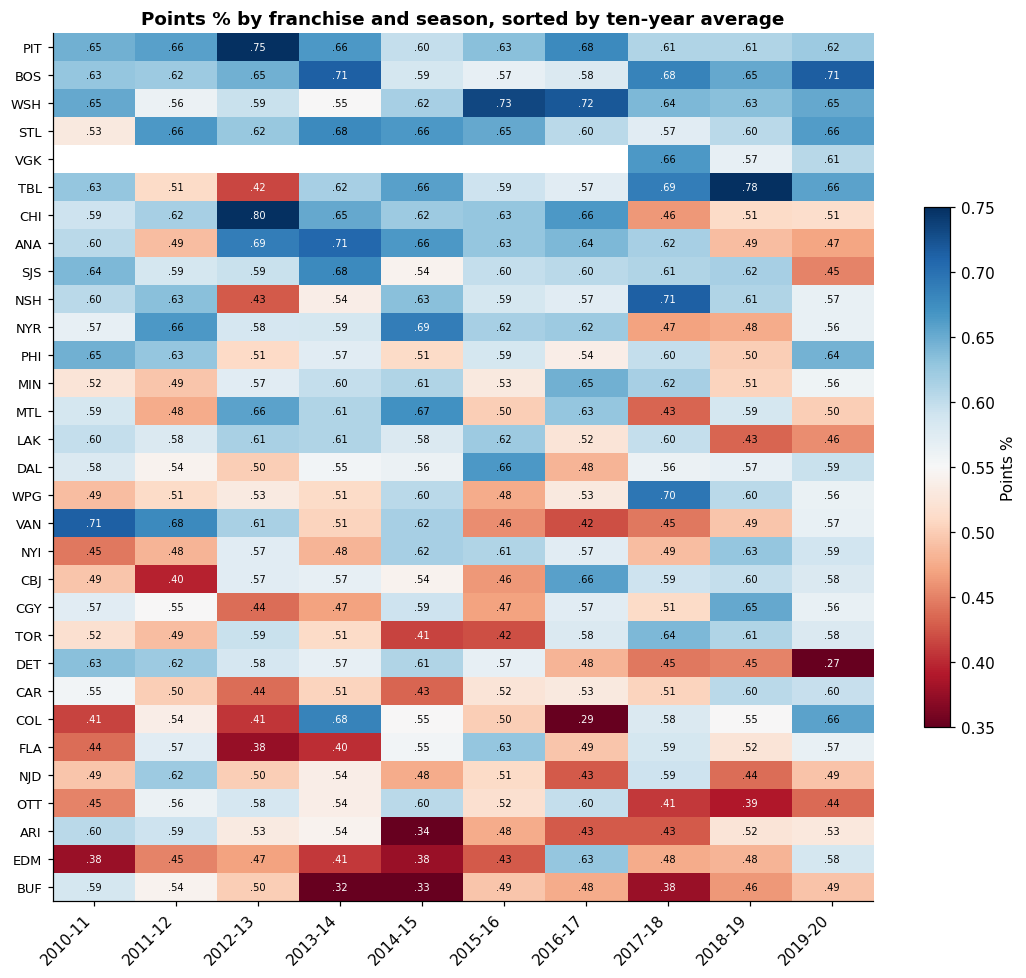

,mean,std,best,worst,range
franchise,,,,,
PIT,0.647,0.045,0.750,0.598,0.152
STL,0.626,0.048,0.677,0.530,0.146
VGK,0.612,0.049,0.665,0.567,0.098
DAL,0.561,0.050,0.665,0.482,0.183
MIN,0.566,0.051,0.646,0.494,0.152
BOS,0.639,0.053,0.714,0.567,0.147
PHI,0.573,0.056,0.646,0.500,0.146
CAR,0.519,0.057,0.604,0.433,0.171
WSH,0.635,0.060,0.732,0.549,0.183


In [6]:
grid = ts.pivot(index="franchise", columns="season", values="points_pct")
grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(grid, cmap="RdBu", vmin=0.35, vmax=0.75, aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=45, ha="right")
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=8.5)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}"[1:], ha="center", va="center", fontsize=6.5,
                    color="white" if abs(v - 0.55) > 0.13 else "black")
ax.grid(False); fig.colorbar(im, shrink=0.6, label="Points %")
ax.set_title("Points % by franchise and season, sorted by ten-year average")
fig.tight_layout(); save(fig, "2_2_points_by_season"); plt.show()

pd.DataFrame({"mean": grid.mean(axis=1), "std": grid.std(axis=1), "best": grid.max(axis=1),
              "worst": grid.min(axis=1), "range": grid.max(axis=1) - grid.min(axis=1)}).sort_values("std").round(3)

**Finding:** Some franchises were steady and others swung widely. Pittsburgh and St. Louis never fell below 0.53, and Pittsburgh's worst season (0.598) would have been above average for most teams. Colorado had the widest range, from a league-worst 0.293 in 2016-17 to 0.683 three seasons earlier, and Detroit declined steadily from 0.63 to 0.275 in 2019-20. Chicago shows the end of a dynasty: 0.80 in 2012-13, then about 0.50 from 2017-18 onward.

### 2.3 Did regular-season success carry into the playoffs?

Each franchise's regular-season points % over the decade against its total playoff wins. The 2019-20 qualifying round counts as playoffs, matching Phase 1. Playoff wins depend on how far a team goes, so they are far noisier than regular-season results.

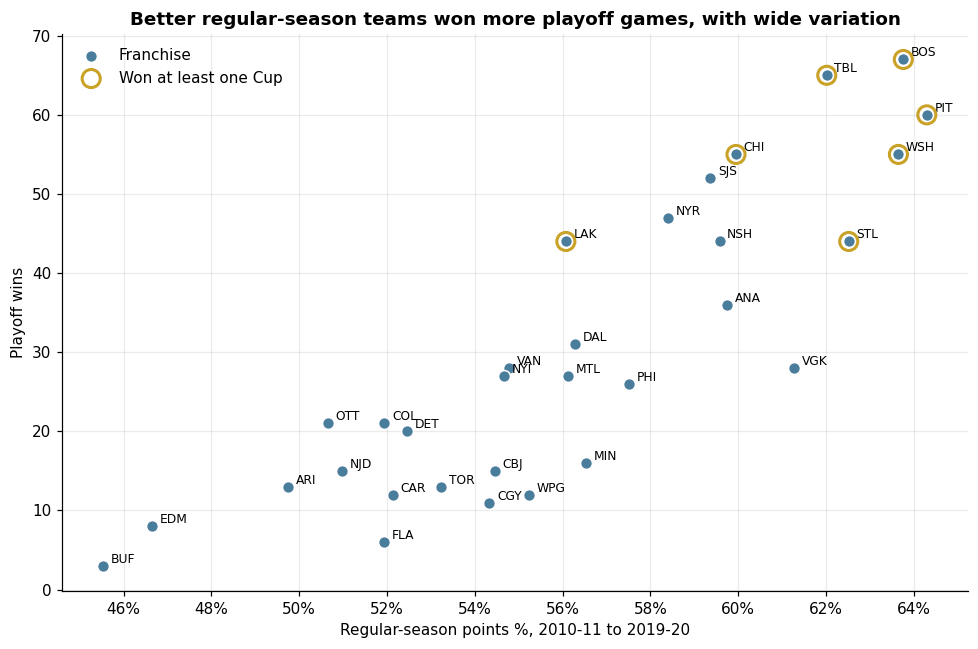

Correlation of regular-season points % with playoff wins: 0.86


,franchise,points_pct,playoff_seasons,playoff_games,playoff_wins,cups
1,BOS,0.638,8,121,67.000,1.000
4,TBL,0.620,7,111,65.000,1.000
0,PIT,0.643,10,115,60.000,2.000
2,WSH,0.636,9,108,55.000,1.000
6,CHI,0.599,8,98,55.000,2.000
9,SJS,0.594,8,101,52.000,0.000
10,NYR,0.584,8,101,47.000,0.000
8,NSH,0.596,8,87,44.000,0.000
15,LAK,0.561,6,79,44.000,2.000
3,STL,0.625,8,93,44.000,1.000


In [7]:
po = q("""
    SELECT f.franchise, count(DISTINCT t.season) AS playoff_seasons, count(*) AS playoff_games,
           sum(t.won::INT) AS playoff_wins
    FROM fact_team_game t JOIN franchise f USING (team_id)
    WHERE t.is_playoff GROUP BY 1""")
po = teams[["franchise", "points_pct"]].merge(po, on="franchise", how="left").fillna(0)
po = po.merge(champions.cup_winner.value_counts().rename("cups"), left_on="franchise", right_index=True, how="left").fillna(0)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(po.points_pct, po.playoff_wins, s=60, color=BLUE, edgecolor="white", lw=1, zorder=3, label="Franchise")
cupw = po[po.cups > 0]
ax.scatter(cupw.points_pct, cupw.playoff_wins, s=140, facecolor="none", edgecolor=GOLD, lw=2, zorder=4,
           label="Won at least one Cup")
for r in po.itertuples():
    ax.annotate(r.franchise, (r.points_pct, r.playoff_wins), xytext=(5, 2), textcoords="offset points", fontsize=8)
pct_axis(ax, "x", step=0.02)
ax.set_xlabel("Regular-season points %, 2010-11 to 2019-20"); ax.set_ylabel("Playoff wins")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Better regular-season teams won more playoff games, with wide variation")
fig.tight_layout(); save(fig, "2_3_regular_vs_playoffs"); plt.show()

r = po[["points_pct", "playoff_wins"]].corr().iloc[0, 1]
print(f"Correlation of regular-season points % with playoff wins: {r:.2f}")
po.sort_values("playoff_wins", ascending=False).round(3)

**Finding:** Over the whole decade, franchises with a better regular-season record won far more playoff games (correlation 0.86). Boston, Tampa Bay, Pittsburgh, Washington and Chicago each won 55 or more playoff games, while Buffalo won 3. The relationship is much stronger over ten years than in any one season (1.2), because a decade of results averages out the luck of individual playoff series. Los Angeles is the clearest exception: two Cups from a 0.561 regular-season record.

# 3. What Wins

### 3.1 Shooting and goaltending: how much is luck?

Every team-season's shooting % against its save %, coloured by points %. The dashed line marks a PDO of 1.00, where the two add up to the league average. Teams far above it had both hot shooting and hot goaltending in that season.

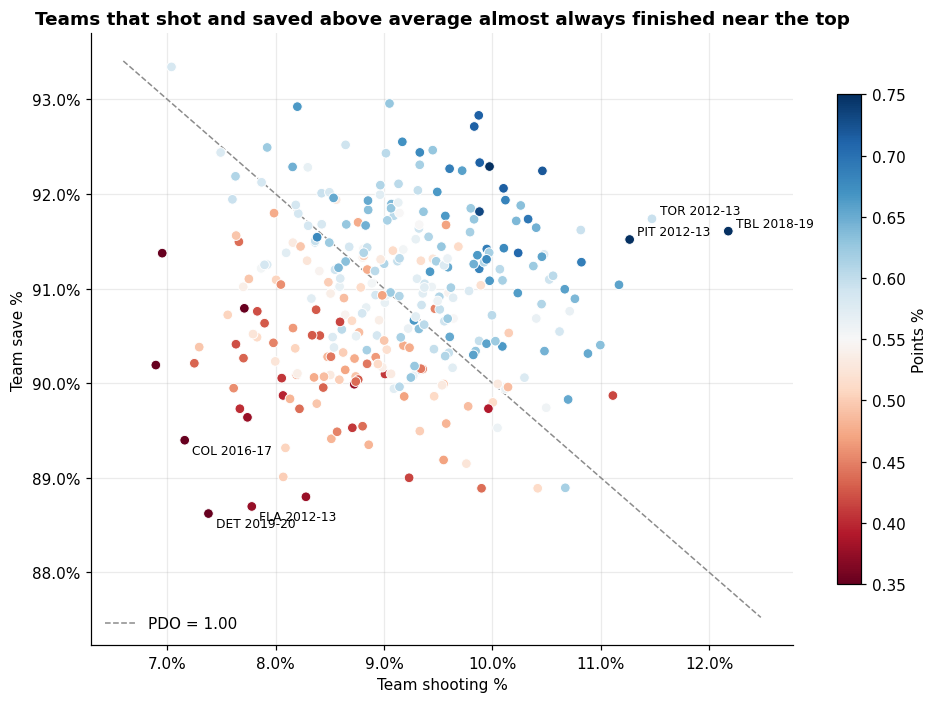

Correlation with points %: {'sh_pct': 0.55, 'sv_pct': 0.59, 'pdo': 0.78, 'shot_share': 0.54}


In [8]:
fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(ts.sh_pct, ts.sv_pct, c=ts.points_pct, cmap="RdBu", vmin=0.35, vmax=0.75, s=40,
                edgecolor="white", lw=0.6, zorder=3)
x = np.linspace(ts.sh_pct.min() - 0.003, ts.sh_pct.max() + 0.003, 10)
ax.plot(x, 1 - x, color=GREY, ls="--", lw=1, label="PDO = 1.00")
for r in ts.nlargest(3, "pdo").itertuples():
    ax.annotate(f"{r.franchise} {r.season}", (r.sh_pct, r.sv_pct), xytext=(5, 3), textcoords="offset points", fontsize=8)
for r in ts.nsmallest(3, "pdo").itertuples():
    ax.annotate(f"{r.franchise} {r.season}", (r.sh_pct, r.sv_pct), xytext=(5, -9), textcoords="offset points", fontsize=8)
pct_axis(ax, "x", 1); pct_axis(ax, "y", 1)
ax.set_xlabel("Team shooting %"); ax.set_ylabel("Team save %"); ax.legend(frameon=False, loc="lower left")
fig.colorbar(sc, shrink=0.8, label="Points %")
ax.set_title("Teams that shot and saved above average almost always finished near the top")
fig.tight_layout(); save(fig, "3_1_shooting_vs_saves"); plt.show()

print("Correlation with points %:",
      ts[["sh_pct", "sv_pct", "pdo", "shot_share"]].corrwith(ts.points_pct).round(2).to_dict())

**Finding:** Shooting % and save % together (PDO) have a correlation of 0.78 with points %, stronger than either one alone (0.55 for shooting and 0.59 for saves) and stronger than shot share (0.54). Nearly every team-season above and to the right of the PDO = 1.00 line finished with a winning record. The extremes are easy to read: Tampa Bay 2018-19 shot 12.2% and finished with 0.780, while Detroit 2019-20 and Colorado 2016-17 combined poor shooting with poor goaltending and finished last. Section 4 shows how little of this carries into the next season.

### 3.2 Which team stats go with a higher points %?

Correlation between each team-season stat and points %. Stats are expressed per game or as a rate, and stats that both teams record (hits, takeaways and so on) are shown as the team's number minus its opponents'. Spearman correlation is used so a few extreme seasons do not dominate.

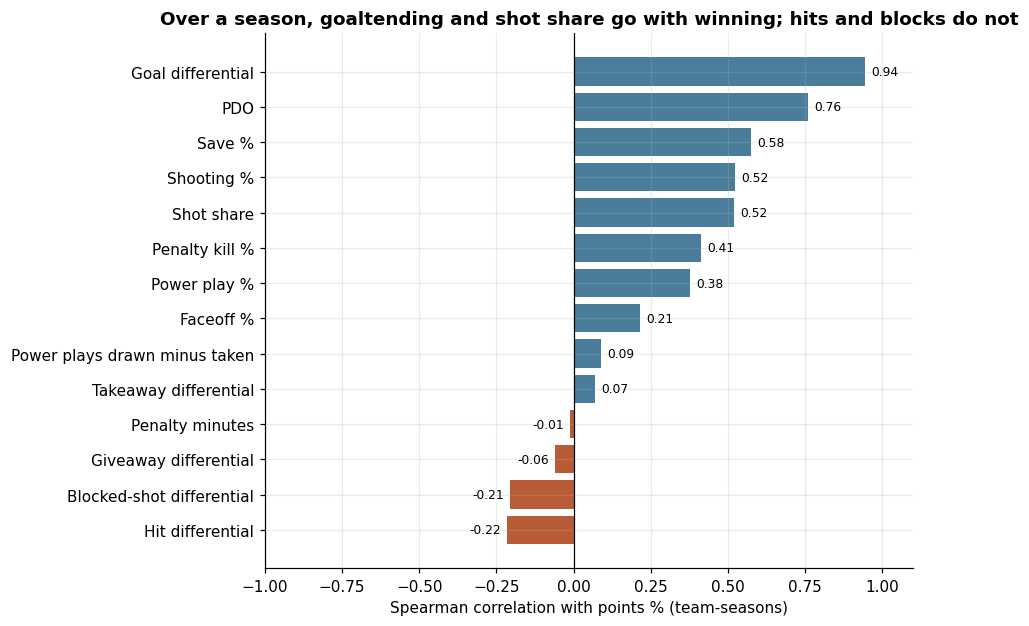

,spearman
Goal differential,0.943
PDO,0.759
Save %,0.575
Shooting %,0.522
Shot share,0.521
Penalty kill %,0.412
Power play %,0.377
Faceoff %,0.215
Power plays drawn minus taken,0.091
Takeaway differential,0.069


In [9]:
stat_labels = {"goal_diff_pg": "Goal differential", "pdo": "PDO", "sv_pct": "Save %", "sh_pct": "Shooting %",
               "shot_share": "Shot share", "pk_pct": "Penalty kill %", "pp_pct": "Power play %",
               "pp_opp_diff_pg": "Power plays drawn minus taken", "faceoff_pct": "Faceoff %",
               "takeaway_diff_pg": "Takeaway differential", "giveaway_diff_pg": "Giveaway differential",
               "block_diff_pg": "Blocked-shot differential", "hit_diff_pg": "Hit differential",
               "pim_pg": "Penalty minutes"}
rho = ts[list(stat_labels)].rank().corrwith(ts.points_pct.rank()).rename(index=stat_labels).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.barh(rho.index, rho.values, color=[RUST if v < 0 else BLUE for v in rho.values])
ax.axvline(0, color="black", lw=0.8)
for y, v in enumerate(rho.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.set_xlim(-1, 1.1); ax.set_xlabel("Spearman correlation with points % (team-seasons)")
ax.set_title("Over a season, goaltending and shot share go with winning; hits and blocks do not")
fig.tight_layout(); save(fig, "3_2_stats_vs_points"); plt.show()
rho.sort_values(ascending=False).to_frame("spearman")

**Finding:** Across team-seasons, the stats most closely tied to points % are goal differential (0.94), PDO (0.76), save % (0.58), shooting % (0.52) and shot share (0.52), followed by special teams (0.41 for the penalty kill and 0.38 for the power play). Faceoffs matter a little (0.21). Takeaways, giveaways, penalty minutes and the power-play count are close to zero, and teams that out-hit and out-block their opponents over a season tend to have slightly lower points % (about -0.2). Hits and blocks are things a team does when it does not have the puck, so a team that hits and blocks a lot is often a team that spends a lot of time defending.

### 3.3 How often does the team that wins a battle also win the game?

Game by game, the share of regular-season games won by the team that came out ahead in each stat: more shots, more faceoff wins, more hits, and so on. Games where both teams were equal in that stat are left out. A bar at 50% would mean winning that battle tells you nothing about the result.

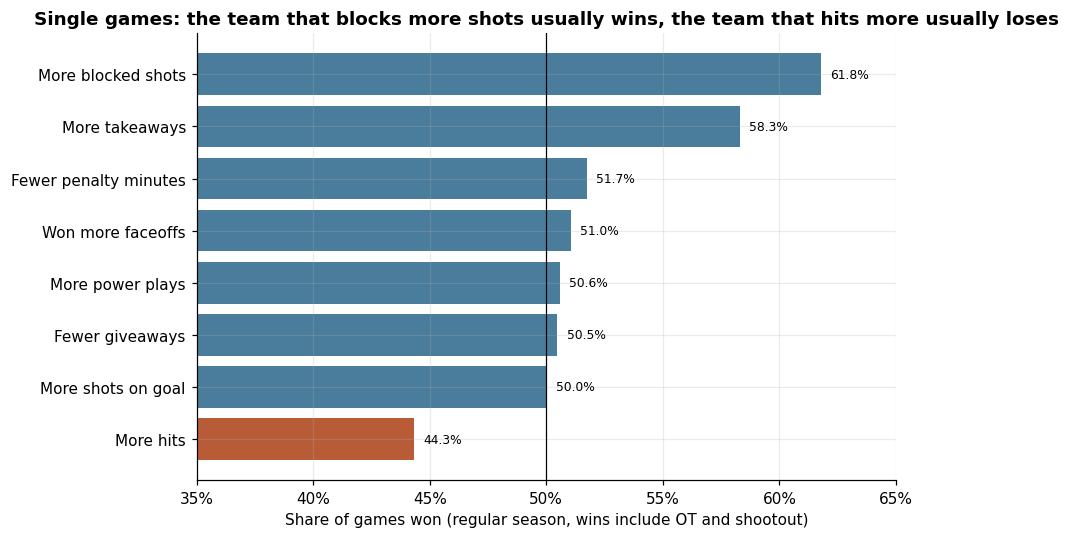

,battle,win_pct,team_games
6,More blocked shots,0.618,11085
2,More takeaways,0.583,10574
5,Fewer penalty minutes,0.517,9365
1,Won more faceoffs,0.510,11151
4,More power plays,0.506,9146
3,Fewer giveaways,0.505,10766
0,More shots on goal,0.500,11285
7,More hits,0.443,11162


In [10]:
battles = {
    "More shots on goal":           "shots_for > shots_against",
    "Won more faceoffs":            "faceoff_win_pct > 0.5",
    "More takeaways":               "takeaways > opp_takeaways",
    "Fewer giveaways":              "giveaways < opp_giveaways",
    "More power plays":             "pp_opportunities > opp_pp_opportunities",
    "Fewer penalty minutes":        "pim < opp_pim",
    "More blocked shots":           "blocked_shots > opp_blocked_shots",
    "More hits":                    "hits > opp_hits",
}
rows = []
for label, cond in battles.items():
    r = q(f"""SELECT avg(won::INT) AS win_pct, count(*) AS games FROM fact_team_game
              WHERE game_type = 'Regular' AND {cond}""").iloc[0]
    rows.append({"battle": label, "win_pct": r.win_pct, "team_games": int(r.games)})
bt = pd.DataFrame(rows).sort_values("win_pct")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(bt.battle, bt.win_pct, color=[BLUE if v >= 0.5 else RUST for v in bt.win_pct])
ax.axvline(0.5, color="black", lw=0.8)
for y, v in enumerate(bt.win_pct):
    ax.text(v + 0.004, y, f"{v:.1%}", va="center", fontsize=8)
pct_axis(ax, "x"); ax.set_xlim(0.35, 0.65)
ax.set_xlabel("Share of games won (regular season, wins include OT and shootout)")
ax.set_title("Single games: the team that blocks more shots usually wins, the team that hits more usually loses")
fig.tight_layout(); save(fig, "3_3_battles_won"); plt.show()
bt.sort_values("win_pct", ascending=False)

**Finding:** Game by game, the picture is different from 3.2 because of score effects. The team that blocked more shots won 62% of the time, yet over a season more blocks went with a lower points %. The reason is that a team with a lead sits back and lets the other team shoot: in third periods, a home team trailing after two periods took 58% of the shots, and a home team leading took 45%. For the same reason, the team that outshot its opponent won exactly 50% of games, even though shot share is one of the better season-level signs of a good team. The team with more hits won only 44%. Takeaways (58%) are inflated by the home scorekeepers: home teams were credited with more takeaways in 63% of games and won more often. Single-game stat comparisons therefore mostly reflect the score and the arena, not team quality.

### 3.4 Special teams: does a good power play or penalty kill matter more?

Each team-season's power-play % against its penalty-kill %, coloured by points %. The dashed lines mark the league averages for the decade.

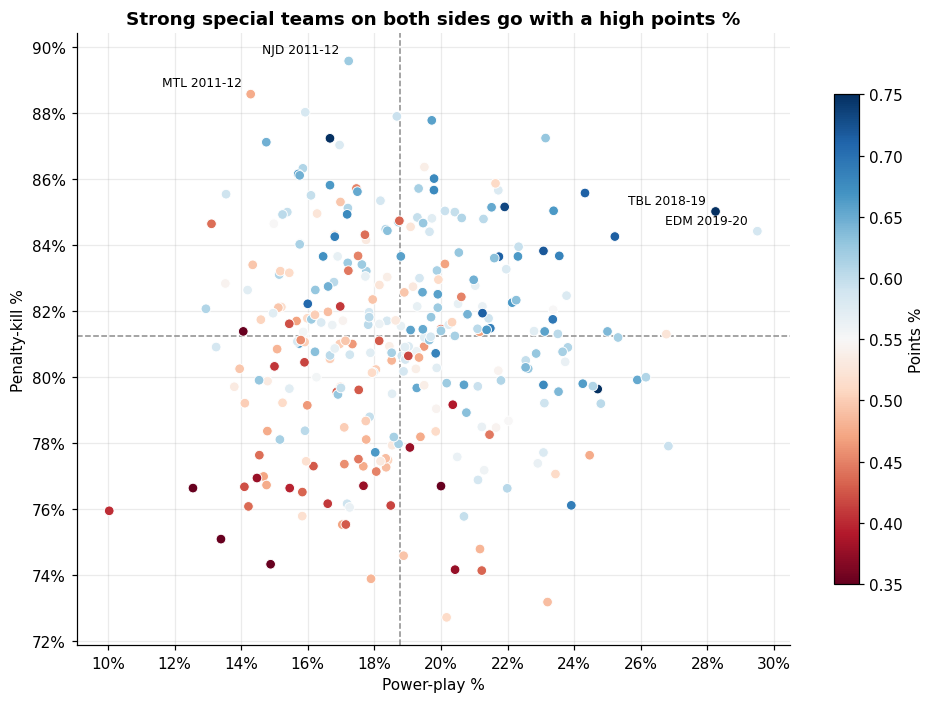

Correlation with points %: {'pp_pct': 0.41, 'pk_pct': 0.45, 'special_teams_index': 0.6, 'pp_opp_diff_pg': 0.11}


In [11]:
lg = q("""SELECT sum(pp_goals) / sum(pp_opportunities) AS pp, 1 - sum(opp_pp_goals) / sum(opp_pp_opportunities) AS pk
          FROM fact_team_game WHERE game_type = 'Regular'""").iloc[0]
fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(ts.pp_pct, ts.pk_pct, c=ts.points_pct, cmap="RdBu", vmin=0.35, vmax=0.75, s=40,
                edgecolor="white", lw=0.6, zorder=3)
ax.axvline(lg.pp, color=GREY, ls="--", lw=1); ax.axhline(lg.pk, color=GREY, ls="--", lw=1)
for r in pd.concat([ts.nlargest(2, "pp_pct"), ts.nlargest(2, "pk_pct")]).itertuples():
    ax.annotate(f"{r.franchise} {r.season}", (r.pp_pct, r.pk_pct), xytext=(-6, 5), textcoords="offset points",
                fontsize=8, ha="right")
pct_axis(ax, "x", step=0.02); pct_axis(ax, "y", step=0.02)
ax.set_xlabel("Power-play %"); ax.set_ylabel("Penalty-kill %")
fig.colorbar(sc, shrink=0.8, label="Points %")
ax.set_title("Strong special teams on both sides go with a high points %")
fig.tight_layout(); save(fig, "3_4_special_teams"); plt.show()

st = ts.assign(special_teams_index=ts.pp_pct + ts.pk_pct)
print("Correlation with points %:",
      st[["pp_pct", "pk_pct", "special_teams_index", "pp_opp_diff_pg"]].corrwith(st.points_pct).round(2).to_dict())

**Finding:** Power-play % and penalty-kill % each have a moderate relationship with points % (0.41 and 0.45). Their sum, a simple special-teams index, does better (0.60). A team can be strong on one and weak on the other, and the best teams were usually above average on both. Tampa Bay 2018-19 had one of the best power plays of the decade (over 28%) together with an above-average penalty kill. The number of power plays drawn minus taken barely matters (0.11): how well a team uses its chances matters much more than how many it gets.

# 4. Repeatability

### 4.1 Which team stats carry over to the next season?

For each franchise and each pair of consecutive seasons, the correlation between a stat in one season and the same stat in the next. A stat that reflects lasting team quality should repeat; a stat driven mostly by luck should not. The second bar shows how well each stat predicts the **next** season's points %, which is what matters for forecasting.

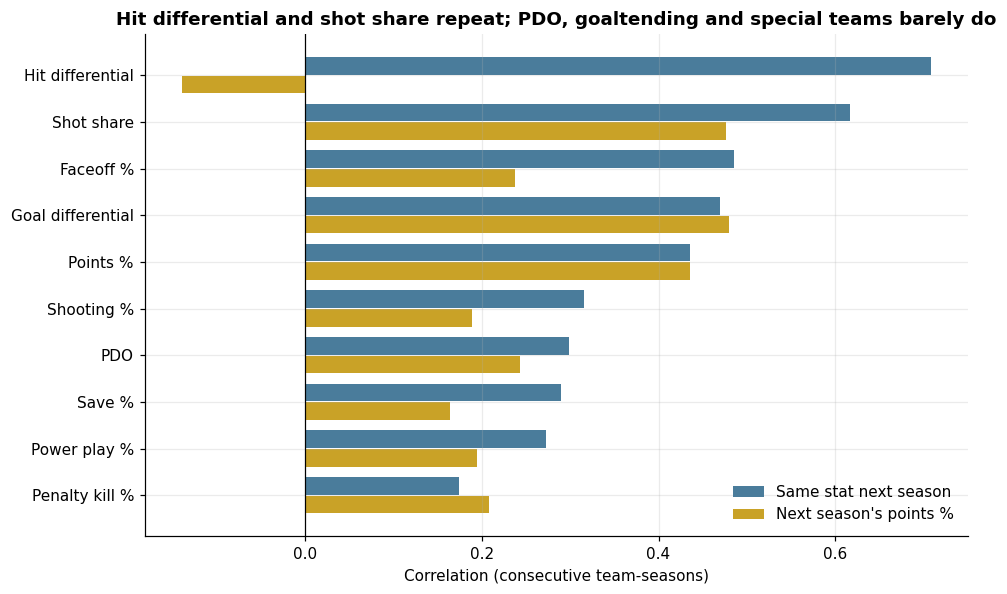

272 pairs of consecutive team-seasons


,same stat next season,next season's points %
Hit differential,0.710,-0.140
Shot share,0.620,0.480
Faceoff %,0.490,0.240
Goal differential,0.470,0.480
Points %,0.440,0.440
Shooting %,0.320,0.190
PDO,0.300,0.240
Save %,0.290,0.160
Power play %,0.270,0.190
Penalty kill %,0.170,0.210


In [12]:
nxt = ts.sort_values("season_start_year").copy()
for c in ["points_pct", "goal_diff_pg", "shot_share", "pdo", "sh_pct", "sv_pct", "pp_pct", "pk_pct",
          "faceoff_pct", "hit_diff_pg"]:
    nxt[f"{c}_next"] = nxt.groupby("franchise")[c].shift(-1)
nxt = nxt[nxt.groupby("franchise").season_start_year.shift(-1) == nxt.season_start_year + 1]

rep_labels = {"points_pct": "Points %", "goal_diff_pg": "Goal differential", "shot_share": "Shot share",
              "pdo": "PDO", "sh_pct": "Shooting %", "sv_pct": "Save %", "pp_pct": "Power play %",
              "pk_pct": "Penalty kill %", "faceoff_pct": "Faceoff %", "hit_diff_pg": "Hit differential"}
rep = pd.DataFrame({
    "same stat next season": {lab: nxt[[c, f"{c}_next"]].corr().iloc[0, 1] for c, lab in rep_labels.items()},
    "next season's points %": {lab: nxt[[c, "points_pct_next"]].corr().iloc[0, 1] for c, lab in rep_labels.items()},
}).sort_values("same stat next season")

fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(rep))
ax.barh(y + 0.2, rep["same stat next season"], height=0.38, color=BLUE, label="Same stat next season")
ax.barh(y - 0.2, rep["next season's points %"], height=0.38, color=GOLD, label="Next season's points %")
ax.set_yticks(y, rep.index); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlation (consecutive team-seasons)"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Hit differential and shot share repeat; PDO, goaltending and special teams barely do")
fig.tight_layout(); save(fig, "4_1_repeatability"); plt.show()
print(f"{len(nxt)} pairs of consecutive team-seasons")
rep.sort_values("same stat next season", ascending=False).round(2)

**Finding:** Hit differential repeats most from one season to the next (0.71), which reflects team style and also the home arena's scorekeepers, who count half of every team's games, but it does not predict next season's points % (-0.14). Shot share repeats well (0.62) and predicts next season's points % (0.48) slightly better than points % itself does (0.44), so it is the best single sign of lasting team quality. Shooting %, save %, PDO and special teams repeat weakly (0.17 to 0.32), so a team that won because of them is likely to fall back. For forecasting, shot share and goal differential are more useful than standings points.

# 5. Coaching Changes

### 5.1 Did changing coaches in mid-season help?

`head_coach` is recorded for every game, so a mid-season coaching change shows up as a new name partway through a team's season. For each change where both coaches ran at least 10 games, the chart compares points % before and after. A team that fires its coach has usually been playing badly, and some of that bad play is bad luck that would have faded anyway, so an improvement after a change is not proof that the new coach caused it.

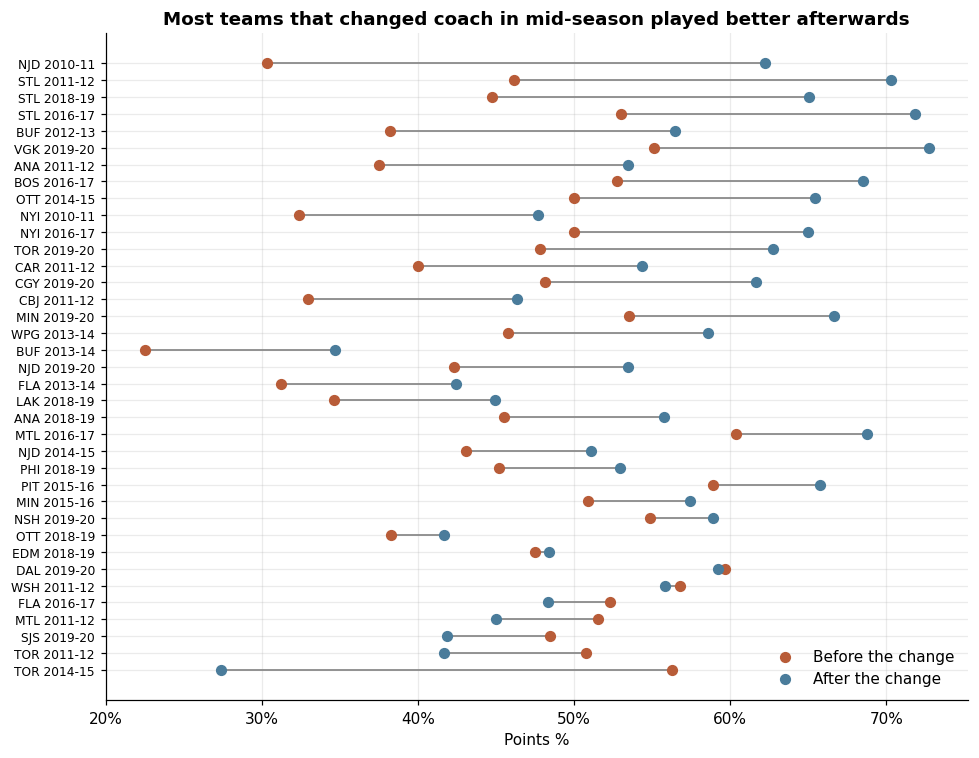

37 mid-season changes; improved in 30; median change +0.112 points %


,franchise,season,head_coach_before,gp_before,points_pct_before,head_coach_after,gp_after,points_pct_after,change,shot_share_before,shot_share_after
2,ANA,2011-12,Randy Carlyle,24,0.375,Bruce Boudreau,58,0.534,0.159,0.460,0.505
12,ANA,2018-19,Randy Carlyle,56,0.455,Bob Murray,26,0.558,0.102,0.445,0.477
33,BOS,2016-17,Claude Julien,55,0.527,Bruce Cassidy,27,0.685,0.158,0.566,0.526
42,BUF,2012-13,Lindy Ruff,17,0.382,Ron Rolston,31,0.565,0.182,0.472,0.445
46,BUF,2013-14,Ron Rolston,20,0.225,Ted Nolan,62,0.347,0.122,0.402,0.444
57,CAR,2011-12,Paul Maurice,25,0.400,Kirk Muller,57,0.544,0.144,0.484,0.485
70,CBJ,2011-12,Scott Arniel,41,0.329,Todd Richards,41,0.463,0.134,0.511,0.473
94,CGY,2019-20,Bill Peters,27,0.481,Geoff Ward,43,0.616,0.135,0.499,0.490
135,DAL,2019-20,Jim Montgomery,31,0.597,Rick Bowness,38,0.592,-0.005,0.499,0.488
165,EDM,2018-19,Todd McLellan,20,0.475,Ken Hitchcock,62,0.484,0.009,0.510,0.469


In [13]:
stints = q("""
    WITH g AS (
        SELECT f.franchise, t.season, t.head_coach, t.game_date_local, t.standings_points, t.goals_for, t.goals_against,
               t.shots_for, t.shots_against
        FROM fact_team_game t JOIN franchise f USING (team_id) WHERE t.game_type = 'Regular'),
    n AS (SELECT *, row_number() OVER (PARTITION BY franchise, season ORDER BY game_date_local) AS game_no FROM g)
    SELECT franchise, season, head_coach, min(game_no) AS first_game, count(*) AS gp,
           sum(standings_points) / (2.0 * count(*)) AS points_pct,
           sum(goals_against) / sum(shots_against) AS opp_sh_pct,
           sum(shots_for) / sum(shots_for + shots_against) AS shot_share
    FROM n GROUP BY ALL ORDER BY franchise, season, first_game""")
stints["stint"] = stints.groupby(["franchise", "season"]).cumcount()
changes = (stints.merge(stints, on=["franchise", "season"], suffixes=("_before", "_after"))
                 .query("stint_after == stint_before + 1 and gp_before >= 10 and gp_after >= 10"))
changes["change"] = changes.points_pct_after - changes.points_pct_before

fig, ax = plt.subplots(figsize=(9, 7))
order = changes.sort_values("change")
y = np.arange(len(order))
ax.hlines(y, order.points_pct_before, order.points_pct_after, color=GREY, lw=1.2)
ax.scatter(order.points_pct_before, y, color=RUST, s=40, zorder=3, label="Before the change")
ax.scatter(order.points_pct_after, y, color=BLUE, s=40, zorder=3, label="After the change")
ax.set_yticks(y, [f"{r.franchise} {r.season}" for r in order.itertuples()], fontsize=8)
pct_axis(ax, "x"); ax.set_xlabel("Points %")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Most teams that changed coach in mid-season played better afterwards")
fig.tight_layout(); save(fig, "5_1_coaching_changes"); plt.show()

print(f"{len(changes)} mid-season changes; improved in {(changes.change > 0).sum()}; "
      f"median change {changes.change.median():+.3f} points %")
changes[["franchise", "season", "head_coach_before", "gp_before", "points_pct_before", "head_coach_after",
         "gp_after", "points_pct_after", "change", "shot_share_before", "shot_share_after"]].round(3)

**Finding:** There were 37 mid-season coaching changes where both coaches ran at least 10 games, and in 30 of them the team's points % improved afterwards, by a median of 11 percentage points. The biggest jumps came from New Jersey in 2010-11 (0.30 to 0.62 after Jacques Lemaire replaced John MacLean) and St. Louis in 2011-12 and 2018-19. Teams change coaches after a bad run, which is often partly bad luck, so some improvement would be expected anyway; this is regression to the mean as much as a coaching effect. Shot share changed far less than points %, which also points to luck evening out rather than a different style of play.

# Summary

**Season recap.** The decade split into a low-scoring first half and a higher-scoring second half, with the jump in 2017-18 driven by shooting % rather than shot volume. Penalties became steadily rarer while power plays became more effective. The best regular-season team won the Cup only once.

**What wins.** Goal differential explains standings almost completely. Shooting and goaltending (PDO) have the strongest season-level relationship with points %, followed by shot share and special teams. Hits and blocks go with spending time without the puck, not with winning.

**Cautions for later analysis.** Single-game stat comparisons are distorted by score effects (leading teams get outshot and block more) and by home scorekeepers (takeaways, giveaways and hits are recorded more generously for the home team). The hits and home-ice notebooks look at the scorekeeper bias in detail.

**What repeats.** Shot share and hit differential carry over from season to season; PDO, goaltending and special teams barely do. Shot share predicts next season's points % at least as well as points % itself.

**Carried forward.** For the skater and goalie notebooks, compare players with rates and against the league average for their season, since the scoring environment changed in 2017-18. Treat a team's shooting % and save % in a single season as partly luck. For the salary model, team context (a player's team quality) varies a lot from year to year, so it should be a feature of the player-season rather than of the player. Team hit counts need the arena adjustment from the hits notebook before they are compared.